# 01. Разведочный анализ данных (EDA)

**Датасет:** Default of Credit Card Clients (UCI), 30 000 клиентов банка на Тайване, апрель–сентябрь 2005.
**Цель модели:** предсказать вероятность дефолта клиента в следующем месяце (`default.payment.next.month`).

Задачи ноутбука:
1. проверить качество данных (пропуски, дубликаты, типы, аномальные коды);
2. понять распределение целевой переменной и связь признаков с дефолтом;
3. обосновать шаги очистки и Feature Engineering, которые реализованы в `src/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd() if (Path.cwd() / "params.yaml").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from src.config import BILL_AMT_COLUMNS, PAY_AMT_COLUMNS, PAY_STATUS_COLUMNS, TARGET
from src.features.build_features import (
    AGE_BINS,
    AGE_LABELS,
    ENGINEERED_NUMERIC_FEATURES,
    NUMERIC_FEATURES,
    build_features,
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
%matplotlib inline

df = pd.read_csv(ROOT / "data" / "raw" / "UCI_Credit_Card.csv")
print("Размер:", df.shape)
df.head()

Размер: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,-2,-2,3913.0,3102.0,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,0,2,2682.0,1725.0,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,0,0,29239.0,14027.0,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,0,0,46990.0,48233.0,49291.0,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,0,0,8617.0,5670.0,35835.0,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


## 1. Описание признаков

| Признак | Описание |
|---|---|
| `LIMIT_BAL` | кредитный лимит (NT$), включая дополнительные карты семьи |
| `SEX` | 1 — мужчина, 2 — женщина |
| `EDUCATION` | 1 — магистратура и выше, 2 — университет, 3 — школа, 4 — другое (0, 5, 6 — недокументированные коды) |
| `MARRIAGE` | 1 — женат/замужем, 2 — холост, 3 — другое (0 — недокументированный код) |
| `AGE` | возраст, лет |
| `PAY_0`, `PAY_2` … `PAY_6` | статус платежа в сентябре … апреле: −2 нет расходов, −1 оплачено полностью, 0 револьверный кредит, 1…9 — просрочка в месяцах |
| `BILL_AMT1` … `BILL_AMT6` | сумма выставленного счёта (сентябрь … апрель) |
| `PAY_AMT1` … `PAY_AMT6` | сумма платежа (сентябрь … апрель) |
| `default.payment.next.month` | **целевая переменная**: 1 — дефолт в октябре |

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_AMT2                   30000 non-null

## 2. Качество данных: пропуски, дубликаты, диапазоны

In [3]:
print("Пропусков всего:", int(df.isna().sum().sum()))
print("Полных дубликатов строк:", int(df.duplicated().sum()))
print("Дубликатов без учёта ID:", int(df.drop(columns="ID").duplicated().sum()))
print("ID уникален:", df["ID"].is_unique)
df.describe().T

Пропусков всего: 0
Полных дубликатов строк: 0
Дубликатов без учёта ID: 35
ID уникален: True


,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0


In [4]:
for column in ["SEX", "EDUCATION", "MARRIAGE", "PAY_0"]:
    print(f"{column}: {sorted(df[column].unique().tolist())}")

SEX: [1, 2]
EDUCATION: [0, 1, 2, 3, 4, 5, 6]
MARRIAGE: [0, 1, 2, 3]
PAY_0: [-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8]


**Наблюдения:**
- пропусков нет, типы числовые — данные чистые технически;
- 35 записей полностью совпадают (кроме `ID`) — удаляем их при подготовке данных (`src/data/make_dataset.py`);
- в `EDUCATION` и `MARRIAGE` встречаются коды, которых нет в описании (0, 5, 6 и 0) — объединяем их с группой «другое»;
- `PAY_x` принимает значения −2 и 0, не описанные в оригинальной документации; по смыслу это «нет расходов» и «револьверный кредит», оставляем как есть;
- эти правила (допустимые коды и диапазоны) зашиты в Great Expectations suite (`src/data/validation.py`).

## 3. Целевая переменная

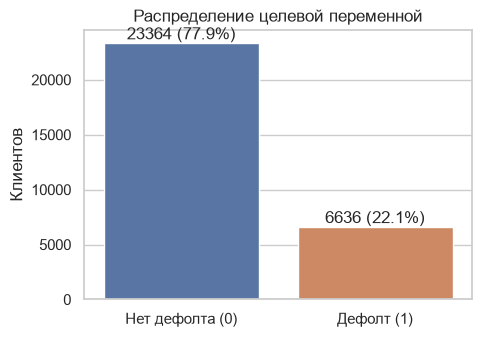

In [5]:
counts = df[TARGET].value_counts().sort_index()
share = df[TARGET].value_counts(normalize=True).sort_index()

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.barplot(x=["Нет дефолта (0)", "Дефолт (1)"], y=counts.values, ax=ax, hue=[0, 1], legend=False)
for i, (n, p) in enumerate(zip(counts.values, share.values)):
    ax.text(i, n, f"{n} ({p:.1%})", ha="center", va="bottom")
ax.set(title="Распределение целевой переменной", ylabel="Клиентов")
plt.show()

Доля дефолтов **≈22%** — умеренный дисбаланс классов. Следствия для моделирования:
- стратифицированное разбиение train/test и стратифицированная кросс-валидация;
- основная метрика — **ROC-AUC** (не зависит от порога и баланса классов), дополнительно PR-AUC;
- порог классификации подбираем (по F1 на out-of-fold предсказаниях), а не берём 0.5 по умолчанию;
- в сетке гиперпараметров пробуем `class_weight="balanced"`.

## 4. Социально-демографические признаки

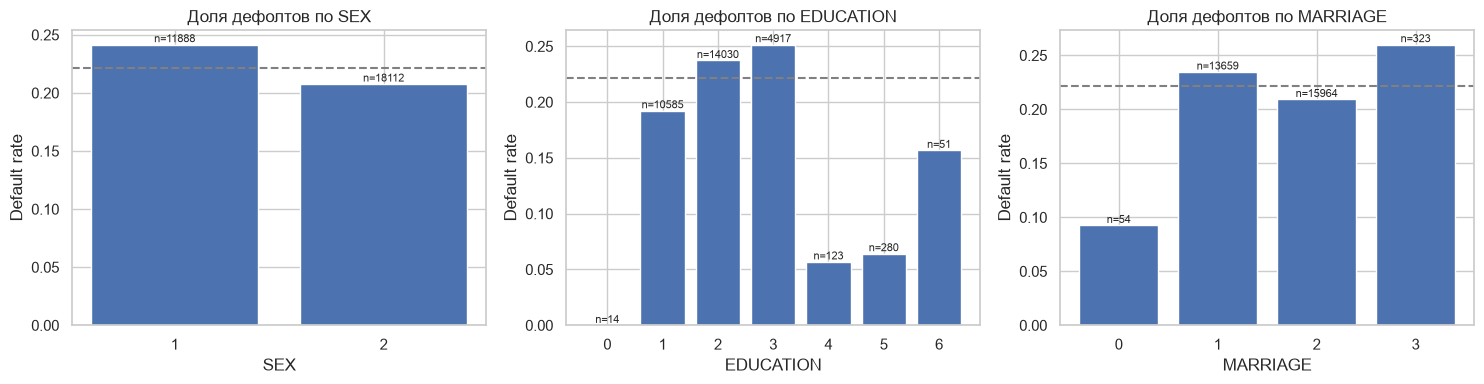

In [6]:
def default_rate_plot(data, column, ax, order=None):
    stats = data.groupby(column)[TARGET].agg(["mean", "size"])
    if order is not None:
        stats = stats.reindex(order)
    ax.bar(stats.index.astype(str), stats["mean"])
    for i, (rate, n) in enumerate(zip(stats["mean"], stats["size"])):
        ax.text(i, rate, f"n={n}", ha="center", va="bottom", fontsize=8)
    ax.axhline(data[TARGET].mean(), ls="--", color="grey")
    ax.set(title=f"Доля дефолтов по {column}", ylabel="Default rate", xlabel=column)


fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, ["SEX", "EDUCATION", "MARRIAGE"]):
    default_rate_plot(df, column, ax)
plt.tight_layout()
plt.show()

- мужчины дефолтят немного чаще (24.2% против 20.8%);
- чем ниже уровень образования, тем выше риск (19% → 24% → 25%); редкие коды 0/4/5/6 (менее 2% клиентов) имеют низкую долю дефолтов — объединяем их в одну группу «другое», чтобы One-Hot Encoding не создавал шумные редкие категории;
- семейное положение влияет слабо.

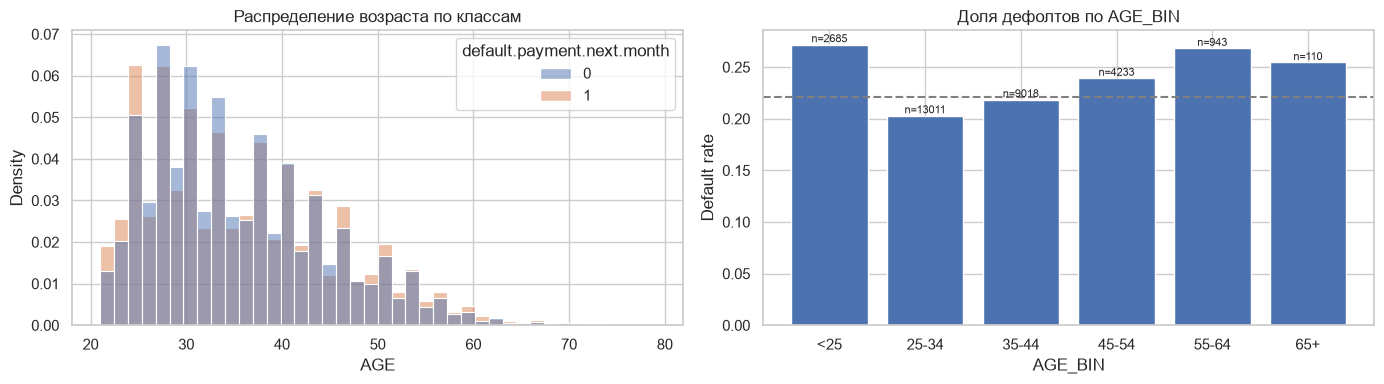

In [7]:
df_age = df.assign(AGE_BIN=pd.cut(df["AGE"], bins=AGE_BINS, labels=AGE_LABELS, right=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=df, x="AGE", hue=TARGET, bins=40, stat="density", common_norm=False, ax=axes[0])
axes[0].set_title("Распределение возраста по классам")
default_rate_plot(df_age, "AGE_BIN", axes[1], order=AGE_LABELS)
plt.tight_layout()
plt.show()

Зависимость риска от возраста **U-образная**: выше всего у молодых (<25 лет, 27%) и у старших (55+), ниже всего в 25–34 года.
Линейная модель не уловит такую форму по «сырому» возрасту — поэтому добавлен признак **`AGE_BIN`** (биннинг возраста), который кодируется One-Hot.

## 5. Кредитный лимит

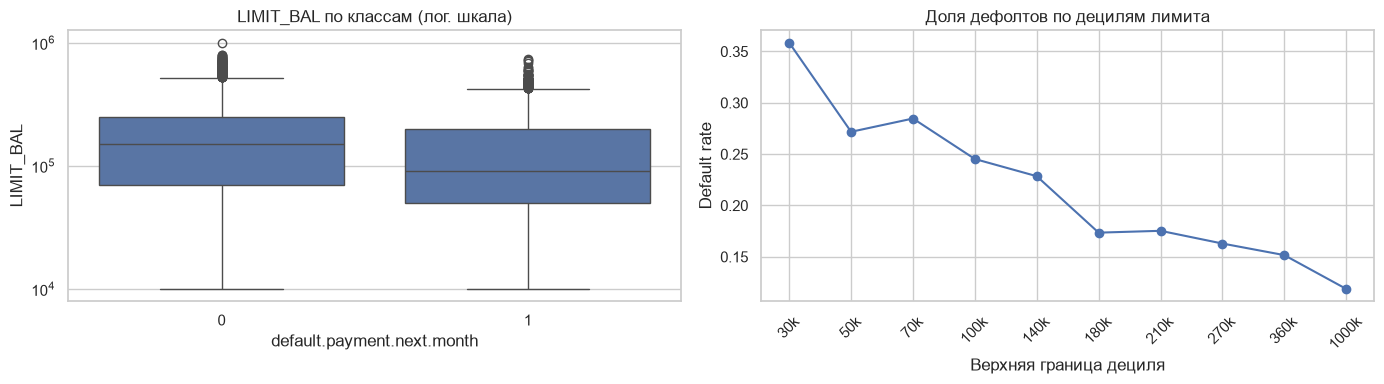

Медианный лимит: {0: 150000.0, 1: 90000.0}


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=df, x=TARGET, y="LIMIT_BAL", ax=axes[0])
axes[0].set(yscale="log", title="LIMIT_BAL по классам (лог. шкала)")

limit_bins = pd.qcut(df["LIMIT_BAL"], q=10, duplicates="drop")
rate = df.groupby(limit_bins, observed=True)[TARGET].mean()
axes[1].plot(range(len(rate)), rate.values, "o-")
axes[1].set_xticks(range(len(rate)), [f"{int(i.right / 1000)}k" for i in rate.index], rotation=45)
axes[1].set(title="Доля дефолтов по децилям лимита", xlabel="Верхняя граница дециля", ylabel="Default rate")
plt.tight_layout()
plt.show()

print("Медианный лимит:", df.groupby(TARGET)["LIMIT_BAL"].median().to_dict())

Клиенты с низким лимитом дефолтят заметно чаще (медиана лимита 90k у дефолтных против 150k у остальных): банк выдаёт большие лимиты более надёжным клиентам. Распределение скошено вправо — для линейной модели применяем стандартизацию.

## 6. История платежей (`PAY_0` … `PAY_6`) — самый сильный сигнал

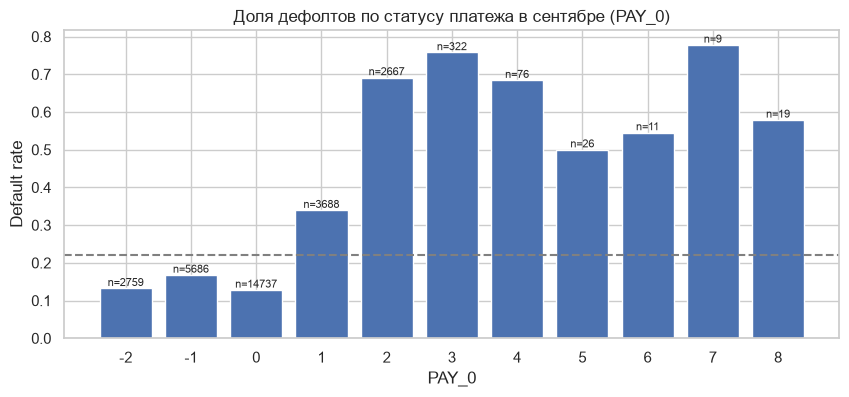

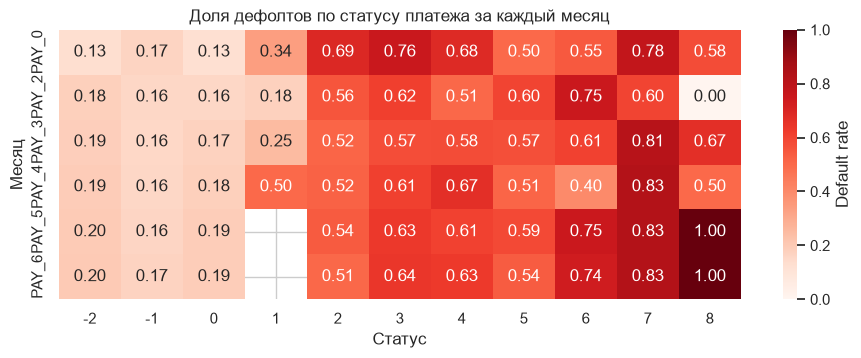

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
default_rate_plot(df, "PAY_0", ax)
ax.set_title("Доля дефолтов по статусу платежа в сентябре (PAY_0)")
plt.show()

rates = pd.DataFrame(
    {col: df.groupby(col)[TARGET].mean() for col in PAY_STATUS_COLUMNS}
).T
fig, ax = plt.subplots(figsize=(11, 3.5))
sns.heatmap(rates, annot=True, fmt=".2f", cmap="Reds", ax=ax, cbar_kws={"label": "Default rate"})
ax.set(title="Доля дефолтов по статусу платежа за каждый месяц", xlabel="Статус", ylabel="Месяц")
plt.show()

- уже **1 месяц просрочки** в сентябре поднимает риск с ~13% до 34%, а **2 месяца — до 69%**;
- чем свежее месяц, тем сильнее связь с дефолтом (`PAY_0` информативнее `PAY_6`);
- зависимость нелинейная (статусы −2, −1, 0 почти не отличаются) — поэтому `PAY_0` подаём в модель как категориальный признак (One-Hot), а также строим агрегаты по всей истории:
  `PAY_DELAY_MAX`, `PAY_DELAY_MEAN`, `N_MONTHS_DELAYED`, `N_MONTHS_NO_CONSUMPTION`.

## 7. Суммы счетов и платежей

In [10]:
amounts = df[BILL_AMT_COLUMNS + PAY_AMT_COLUMNS]
summary = pd.DataFrame(
    {
        "skew": amounts.skew(),
        "share_negative": (amounts < 0).mean(),
        "share_zero": (amounts == 0).mean(),
    }
).round(3)
print("Клиентов хотя бы с одним отрицательным счётом (переплата):",
      f"{(df[BILL_AMT_COLUMNS] < 0).any(axis=1).mean():.1%}")
summary

Клиентов хотя бы с одним отрицательным счётом (переплата): 6.4%


,skew,share_negative,share_zero
BILL_AMT1,2.664,0.020,0.067
BILL_AMT2,2.705,0.022,0.084
BILL_AMT3,3.088,0.022,0.096
BILL_AMT4,2.822,0.022,0.106
BILL_AMT5,2.876,0.022,0.117
BILL_AMT6,2.847,0.023,0.134
PAY_AMT1,14.668,0.000,0.175
PAY_AMT2,30.454,0.000,0.180
PAY_AMT3,17.217,0.000,0.199
PAY_AMT4,12.905,0.000,0.214


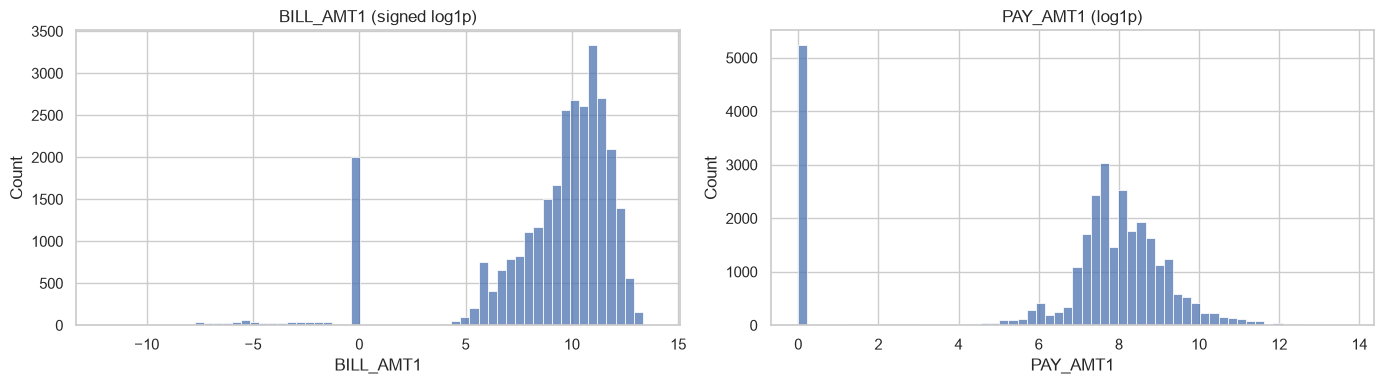

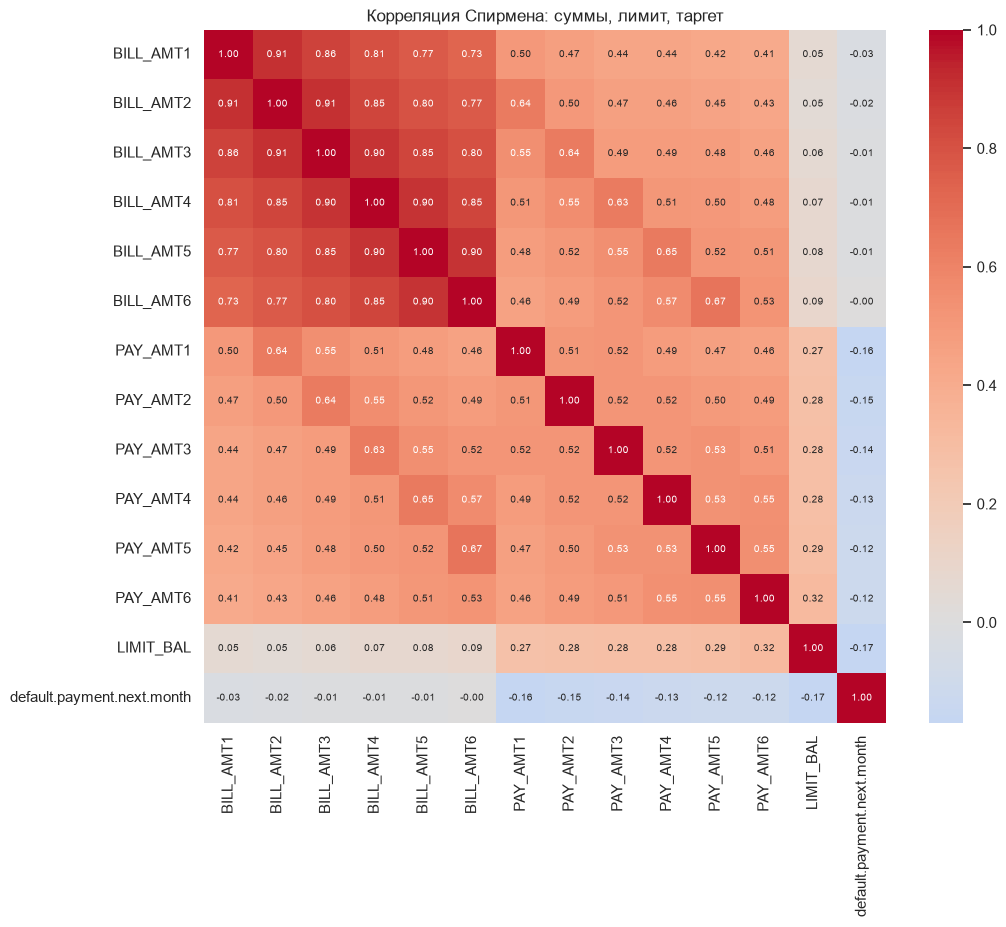

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(np.sign(df["BILL_AMT1"]) * np.log1p(df["BILL_AMT1"].abs()), bins=60, ax=axes[0])
axes[0].set_title("BILL_AMT1 (signed log1p)")
sns.histplot(np.log1p(df["PAY_AMT1"]), bins=60, ax=axes[1])
axes[1].set_title("PAY_AMT1 (log1p)")
plt.tight_layout()
plt.show()

corr = df[BILL_AMT_COLUMNS + PAY_AMT_COLUMNS + ["LIMIT_BAL", TARGET]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Корреляция Спирмена: суммы, лимит, таргет")
plt.show()

- суммы сильно скошены (skew PAY_AMT1 ≈ 15), много нулевых платежей (17.5% в сентябре), есть отрицательные счета (переплата) — это нормальные значения, а не ошибки; в правилах валидации допускаем отрицательные `BILL_AMT`, но не `PAY_AMT`;
- счета соседних месяцев коррелируют очень сильно (r ≥ 0.8) — мультиколлинеарность; для логистической регрессии это повод для регуляризации (подбираем `C`), а для деревьев не критично;
- сами по себе суммы связаны с дефолтом слабо, важнее **относительные** показатели: загрузка лимита (`UTILIZATION_*`), доля оплаченного счёта (`PAY_TO_BILL_RATIO`), рост долга (`BILL_GROWTH`).

## 8. Проверка инженерных признаков

Сравним предсказательную силу признаков по одному: ROC-AUC одного признака (ориентация выбирается так, чтобы AUC ≥ 0.5).
Инженерные признаки считаются той же функцией `build_features`, что используется в модели и API.

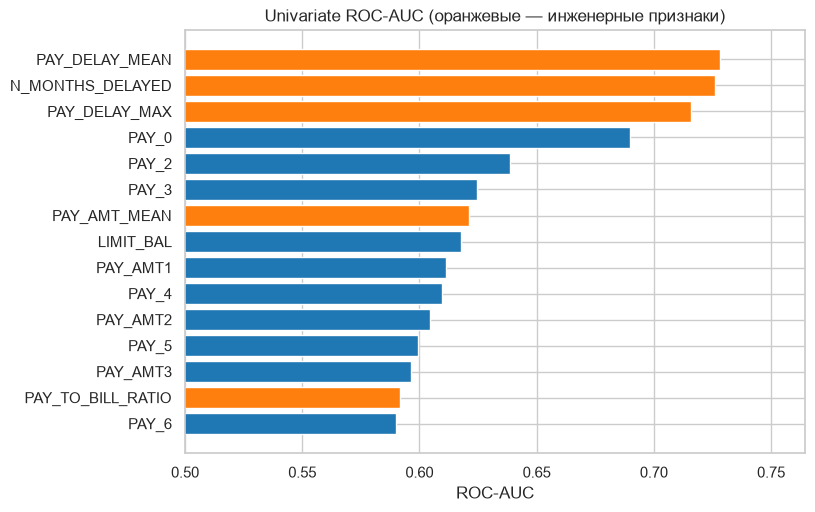

,univariate_roc_auc
PAY_DELAY_MEAN,0.728
N_MONTHS_DELAYED,0.726
PAY_DELAY_MAX,0.716
PAY_0,0.690
PAY_2,0.639
PAY_3,0.624
PAY_AMT_MEAN,0.621
LIMIT_BAL,0.618
PAY_AMT1,0.611
PAY_4,0.610


In [12]:
features = build_features(df)


def univariate_auc(values, target):
    auc = roc_auc_score(target, values)
    return max(auc, 1 - auc)


auc = pd.Series(
    {column: univariate_auc(features[column], features[TARGET]) for column in NUMERIC_FEATURES + ["PAY_0"]}
).sort_values(ascending=False)
top = auc.head(15)

colors = ["tab:orange" if c in ENGINEERED_NUMERIC_FEATURES else "tab:blue" for c in top.index]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.index[::-1], top.values[::-1], color=colors[::-1])
ax.set(xlim=(0.5, None), title="Univariate ROC-AUC (оранжевые — инженерные признаки)", xlabel="ROC-AUC")
plt.show()
top.round(3).to_frame("univariate_roc_auc")

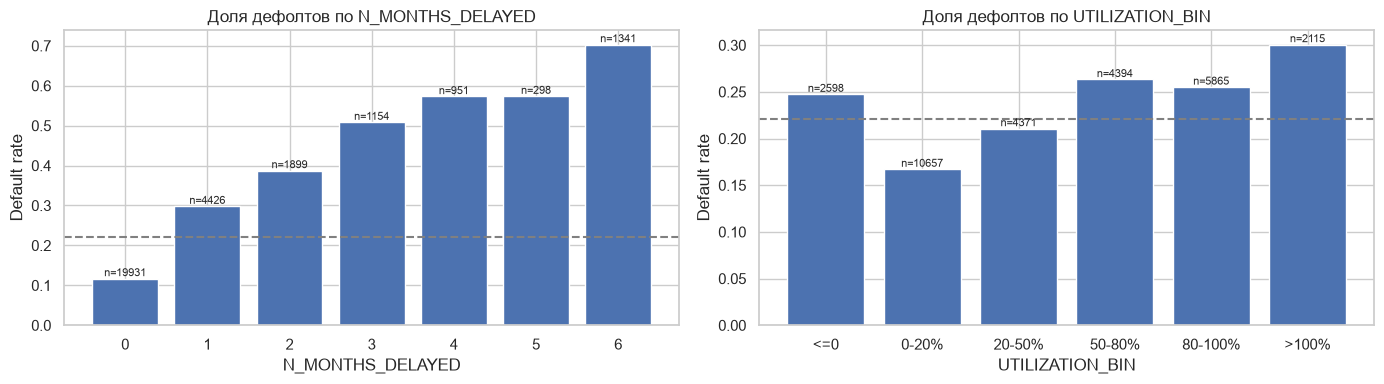

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
default_rate_plot(features, "N_MONTHS_DELAYED", axes[0])
features["UTILIZATION_BIN"] = pd.cut(
    features["UTILIZATION_LAST"], [-np.inf, 0, 0.2, 0.5, 0.8, 1.0, np.inf],
    labels=["<=0", "0-20%", "20-50%", "50-80%", "80-100%", ">100%"],
)
default_rate_plot(features, "UTILIZATION_BIN", axes[1], order=["<=0", "0-20%", "20-50%", "50-80%", "80-100%", ">100%"])
plt.tight_layout()
plt.show()

**Инженерные признаки сильнее исходных:** `PAY_DELAY_MEAN`, `N_MONTHS_DELAYED` и `PAY_DELAY_MAX` имеют univariate ROC-AUC ≈ 0.72–0.73 против 0.69 у лучшего сырого признака `PAY_0`.
Доля дефолтов монотонно растёт с числом месяцев просрочки (12% → 70%) и с загрузкой лимита.

## 9. Выводы EDA → решения в пайплайне

| Наблюдение | Решение в коде |
|---|---|
| 35 дубликатов, технический `ID` | удаляются в `make_dataset.clean_data` |
| недокументированные коды EDUCATION/MARRIAGE | объединяются в «другое» (`consolidate_categories`), допустимые коды проверяет GE |
| дисбаланс 78/22 | стратификация, ROC-AUC/PR-AUC, подбор порога, `class_weight` в сетке |
| U-образный риск по возрасту | признак `AGE_BIN` |
| история просрочек — главный сигнал, нелинейна | `PAY_0` как категория + агрегаты `PAY_DELAY_*`, `N_MONTHS_*` |
| суммы скошены, важны относительные величины | `UTILIZATION_*`, `PAY_TO_BILL_RATIO`, `BILL_GROWTH`, StandardScaler |
| сильная корреляция `BILL_AMT*` | регуляризация логрегрессии, ансамбли деревьев |